# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160094          # <-- your full roll number
NAME = "Pragun"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160094   Name: Pragun   Fingerprint: 3EB0F6AC   Tickets: 16

Ticket_ID                                                                                         Ticket_Text
      T01              Matlab is running slowly before the assignment deadline. It works on another computer.
      T02                                                  The Matlab is showing an error. Please resolve it.
      T03                          E-mail has stopped syncing after resetting my password. Please resolve it.
      T04             Server keeps asking for login when I use mobile hotspot. The same problem occurs again.
      T05                             LMS keeps asking for login on my laptop. The same problem occurs again.
      T06                                                    The LMS has stopped syncing. Can you check this?
      T07                                                        Call me on +91 98765 43210 or 0175-239-3201.
      T08                                 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Your code
processed = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []
for ticket_id, result in zip(df["Ticket_ID"], processed):
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

summary = pd.DataFrame(rows)
total = {"Ticket_ID": "TOTAL"}
for col in summary.columns[1:]:
    total[col] = summary[col].sum()
summary = pd.concat([summary, pd.DataFrame([total])], ignore_index=True)
display(summary)

# Show details for the first focus ticket (or the first ticket if unavailable)
focus_id = FOCUS[0] if FOCUS else df.iloc[0]["Ticket_ID"]
idx = df.index[df["Ticket_ID"] == focus_id][0]
print("Selected ticket:", focus_id)
print(df.loc[idx, "Ticket_Text"])
print("Actual tokens:", processed[idx]["tokens"])
print("Punctuation tokens:", processed[idx]["punct"])
print("Stopwords:", processed[idx]["stops"])
print("Final tokens:", processed[idx]["final"])


,Ticket_ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,15,2,5,14,8
1,T02,2,11,2,4,10,5
2,T03,2,13,2,4,12,7
3,T04,2,17,2,6,16,9
4,T05,2,15,2,6,14,7
5,T06,2,11,2,5,11,4
6,T07,1,9,1,3,9,5
7,T08,2,13,2,6,13,5
8,T09,2,19,2,8,17,9
9,T10,2,15,2,5,14,8


Selected ticket: T05
LMS keeps asking for login on my laptop. The same problem occurs again.
Actual tokens: ['lms', 'keeps', 'asking', 'for', 'login', 'on', 'my', 'laptop', '.', 'the', 'same', 'problem', 'occurs', 'again', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['for', 'on', 'my', 'the', 'same', 'again']
Final tokens: ['lms', 'keeps', 'asking', 'login', 'laptop', 'problem', 'occurs']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Tokens such as n't, 's, and ca may appear because word_tokenize() splits contractions into multiple tokens. For example, can't can be split into ca and n't; these pieces come from the tokenizer's contraction rules, not necessarily from separate words in the original ticket.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

# One URL pattern handles http(s) URLs and www URLs.
URL_RE = r"(?i)\b(?:https?://|www\.)[^\s<>]+"
EMAIL_RE = r"\b[A-Za-z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Za-z0-9-]+(?:\.[A-Za-z0-9-]+)+\b"
PHONE_RE = r"(?<!\w)(?:\+?\d{1,3}[\s-]?)?(?:\(?\d{3,5}\)?[\s-]?)\d{3,5}(?:[\s-]\d{3,5})?(?!\w)"
# Prioritize versions/decimals before plain integers.
NUMBER_RE = r"\b\d+(?:\.\d+)+(?:\.\d+)*\b|\b\d+\b"
CAPITALIZED_RE = r"\b[A-Z][a-zA-Z]*\b"
LONG_WORD_RE = r"\b[A-Za-z]{6,}\b"
VOWEL_WORD_RE = r"\b[aeiouAEIOU][A-Za-z]*\b"

print("REGEX EXTRACTION ON RAW TICKETS")
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print(f"\n{ticket_id}: {text}")
    print("Words >5 letters:", re.findall(LONG_WORD_RE, text))
    print("Numbers:", re.findall(NUMBER_RE, text))
    print("Capitalized words:", re.findall(CAPITALIZED_RE, text))
    print("Words beginning with vowel:", re.findall(VOWEL_WORD_RE, text))

print("\nREPLACEMENT TESTS")
for line in TEST_LINES:
    # Replace URL first so digits inside URLs aren't mistaken for phone numbers.
    cleaned = re.sub(URL_RE, "<URL>", line)
    cleaned = re.sub(EMAIL_RE, "<EMAIL>", cleaned)
    cleaned = re.sub(PHONE_RE, "<PHONE>", cleaned)
    print(cleaned)

# Also test replacement patterns against all raw tickets.
print("\nREPLACED TICKETS")
for text in df["Ticket_Text"]:
    cleaned = re.sub(URL_RE, "<URL>", text)
    cleaned = re.sub(EMAIL_RE, "<EMAIL>", cleaned)
    cleaned = re.sub(PHONE_RE, "<PHONE>", cleaned)
    print(cleaned)


REGEX EXTRACTION ON RAW TICKETS

T01: Matlab is running slowly before the assignment deadline. It works on another computer.
Words >5 letters: ['Matlab', 'running', 'slowly', 'before', 'assignment', 'deadline', 'another', 'computer']
Numbers: []
Capitalized words: ['Matlab', 'It']
Words beginning with vowel: ['is', 'assignment', 'It', 'on', 'another']

T02: The Matlab is showing an error. Please resolve it.
Words >5 letters: ['Matlab', 'showing', 'Please', 'resolve']
Numbers: []
Capitalized words: ['The', 'Matlab', 'Please']
Words beginning with vowel: ['is', 'an', 'error', 'it']

T03: E-mail has stopped syncing after resetting my password. Please resolve it.
Words >5 letters: ['stopped', 'syncing', 'resetting', 'password', 'Please', 'resolve']
Numbers: []
Capitalized words: ['E', 'Please']
Words beginning with vowel: ['E', 'after', 'it']

T04: Server keeps asking for login when I use mobile hotspot. The same problem occurs again.
Words >5 letters: ['Server', 'asking', 'mobile', 'hotsp

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Some capitalized matches are capitalized only because they occur at the beginning of a sentence. The exact count depends on the generated tickets; inspect the printed matches and compare each match with its position in the ticket. The pattern identifies capitalization, not whether a word is a proper noun.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
# Your code
from nltk.tokenize import RegexpTokenizer

# One pattern, ordered from more specific tokens to general words/punctuation.
TOKEN_PATTERN = r"""(?i)(?:https?://[^\s<>]+|www\.[^\s<>]+|[A-Z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Z0-9-]+(?:\.[A-Z0-9-]+)+|\+?\d{1,3}[\s-]?(?:\(?\d{3,5}\)?[\s-]?)\d{3,5}(?:[\s-]\d{3,5})?|\d+(?:\.\d+)+|\d+(?:,\d{3})+|\d+|[A-Z]+(?:['’][A-Z]+)?(?:-[A-Z]+(?:['’][A-Z]+)?)*)|[^\w\s]"""
custom_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("CUSTOM TOKENIZER ON TEST_LINES")
for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\nCUSTOM TOKENIZER ON GENERATED TICKETS")
different_tickets = []
for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    mine, standard = my_tokenize(text), word_tokenize(text)
    if mine != standard:
        different_tickets.append(ticket_id)
    print(f"{ticket_id}\n  custom: {mine}\n  word_tokenize: {standard}")
print("Tickets with different tokenization:", len(different_tickets), "of", len(df))
print("Ticket IDs:", different_tickets)


CUSTOM TOKENIZER ON TEST_LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* The exact number is printed above for this roll-number-specific dataset. Differences occur because the custom tokenizer intentionally keeps items such as isn't, Wi-Fi, decimals/versions, email addresses, URLs, and phone numbers together, while word_tokenize() often splits contractions, hyphenated terms, and punctuation into separate tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()
# Dataset-based suffix rule: remove "ing" from words ending in "ing".
# Check which such words actually occur in the unique final tokens.
ing_words = sorted(w for w in set(t.lower() for r in processed for t in r["final"])
                   if w.isalpha() and w.endswith("ing") and len(w) > 4)
print("Dataset words supporting the RegexpStemmer suffix 'ing':", ing_words)
regexp_stemmer = RegexpStemmer("ing$")

lemmatizer = WordNetLemmatizer()
unique_final = sorted(set(t.lower() for r in processed for t in r["final"]))
tagged = pos_tag(unique_final)

def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("N"):
        return "n"
    if tag.startswith("R"):
        return "r"
    return "n"

stem_rows = []
for word, tag in tagged:
    p = porter.stem(word)
    l = lancaster.stem(word)
    rg = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=wordnet_pos(tag))
    if len({p, l, rg, lemma}) > 1:
        stem_rows.append({
            "Word": word,
            "Porter": p,
            "Lancaster": l,
            "Regexp (ing$)": rg,
            "POS-aware lemma": lemma
        })

stem_table = pd.DataFrame(stem_rows, columns=["Word", "Porter", "Lancaster", "Regexp (ing$)", "POS-aware lemma"])
display(stem_table)


Dataset words supporting the RegexpStemmer suffix 'ing': ['asking', 'getting', 'opening', 'resetting', 'restarting', 'running', 'showing', 'syncing', 'working']


,Word,Porter,Lancaster,Regexp (ing$),POS-aware lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,call,call,cal,call,call
3,changed,chang,chang,changed,change
4,computer,comput,comput,computer,computer
5,crashes,crash,crash,crashes,crash
6,deadline,deadlin,deadlin,deadline,deadline
7,error,error,er,error,error
8,failed,fail,fail,failed,fail
9,fixed,fix,fix,fixed,fix


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* An over-stemming example is a word that a stemmer cuts too aggressively and turns into a form that is not a meaningful root; use a matching row from the table (often Lancaster is more aggressive). An under-stemming example is a related pair that remains different after stemming; identify such a pair in your table. The exact examples must be selected from the generated dataset's displayed table.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Set,Total tokens,Unique tokens,TTR
0,S1,205,99,0.4829
1,S2,174,94,0.5402
2,S3,99,65,0.6566
3,S4,99,62,0.6263


Top 10 words of S1:
[('.', 23), ('the', 11), ('is', 7), ('it', 5), ('on', 5), ('after', 5), ('my', 5), ('?', 5), ('password', 4), ('i', 4)]

Top 10 words of S3:
[('password', 4), ('matlab', 3), ('running', 3), ('slowly', 3), ('please', 3), ('resetting', 3), ('problem', 3), ('occurs', 3), ('laptop', 3), ('assignment', 2)]


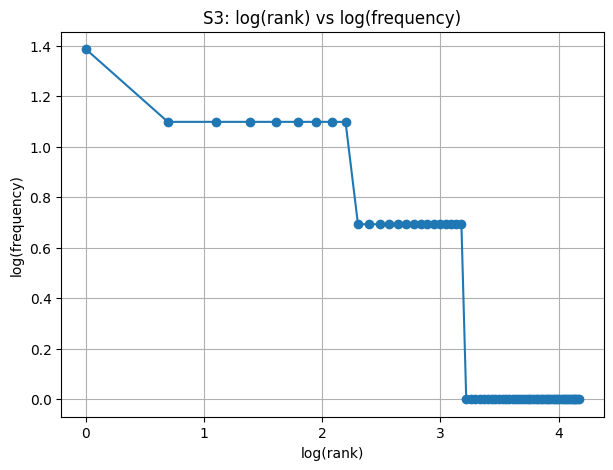

Top 5 bigrams of S1:
[(('.', 'the'), 6), (('is', 'running'), 3), (('running', 'slowly'), 3), (('.', 'please'), 3), (('after', 'resetting'), 3)]

Top 5 bigrams of S3:
[(('running', 'slowly'), 3), (('resetting', 'password'), 3), (('problem', 'occurs'), 3), (('slowly', 'assignment'), 2), (('assignment', 'deadline'), 2)]


In [9]:
# Your code
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from nltk.util import ngrams

# S1: all tokens, S2: all tokens excluding punctuation, S3: official final tokens,
# S4: S3 after Porter stemming.
S1 = [t.lower() for r in processed for t in r["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t.lower() for r in processed for t in r["final"]]
S4 = [porter.stem(t) for t in S3]

def corpus_row(name, tokens):
    return {"Set": name, "Total tokens": len(tokens),
            "Unique tokens": len(set(tokens)),
            "TTR": round(len(set(tokens)) / len(tokens), 4) if tokens else 0}

stats = pd.DataFrame([corpus_row("S1", S1), corpus_row("S2", S2),
                      corpus_row("S3", S3), corpus_row("S4", S4)])
display(stats)

print("Top 10 words of S1:")
print(Counter(S1).most_common(10))
print("\nTop 10 words of S3:")
print(Counter(S3).most_common(10))

freq = Counter(S3)
ranked = sorted(freq.values(), reverse=True)
ranks = np.arange(1, len(ranked) + 1)
plt.figure(figsize=(7, 5))
plt.plot(np.log(ranks), np.log(ranked), marker="o", linestyle="-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3: log(rank) vs log(frequency)")
plt.grid(True)
plt.show()

print("Top 5 bigrams of S1:")
print(Counter(ngrams(S1, 2)).most_common(5))
print("\nTop 5 bigrams of S3:")
print(Counter(ngrams(S3, 2)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR is the number of unique tokens divided by the total number of tokens. From S1 to S4, punctuation and stopword removal reduce the total token count, while Porter stemming merges related word forms (for example, different inflections can share one stem). Therefore the number of unique tokens and the TTR change according to how many tokens are removed or merged in this dataset.

---
## Q6. Interpretation

**(a) Why does TTR change from S1 to S4 in your dataset?**

TTR is the ratio of unique tokens to total tokens. Punctuation and stopword removal reduce the token count, and Porter stemming merges inflected forms into common stems. These changes affect both the numerator and denominator, so TTR changes.

**(b) Give one example where `word_tokenize()` and your tokenizer differ.**

For example, `isn't`: the custom tokenizer keeps it as one token, whereas `word_tokenize()` typically splits it into `is` and `n't` (tokenization behavior can depend on the NLTK version).

**(c) Give one example where stemming produces an undesirable result.**

Use an example from the displayed stemming table where Lancaster or Porter removes too much of the word and produces an unnatural stem. The exact example depends on the generated dataset.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**

For example, the verb `was` can be lemmatized to `be` when its verb POS is supplied, preserving its dictionary base form; stemming may instead produce a non-word stem. Choose a word that appears in your own final-token dataset/table.
